
# Ride-Sharing Simulation and Performance Analysis

### SENG 331 - Modeling and Simulation
### Jupyter Notebook - Weeks 1-3 Analysis

## 1. Project Overview

This project aims to model and analyze a ride-sharing system using discrete-event simulation (DES) and the SimPy framework.

The simulation represents customer arrivals, driver assignments, pickup processes, trip completions, and customer abandonment.

The main objectives are:

- To analyze customer waiting times.
- To evaluate driver utilization.
- To examine queue length over time, Q(t).
- To observe the number of busy drivers over time, B(t).
- To visualize customer status transitions through a schematic 2D animation.

The notebook presents the simulation configuration, performance metrics, graphical results, and preliminary analysis of system behavior.


In [1]:

# 2. Import Libraries

import simpy
import matplotlib.pyplot as plt

from dataclasses import asdict
from config import SimulationConfig
from simulation import RideSharingSimulation
from simulation_plots import plot_q_b

%matplotlib inline

print("All libraries imported successfully.")


All libraries imported successfully.


In [2]:

# 3. Simulation Configuration

config = SimulationConfig()

print("Simulation Parameters")
print("-" * 40)

for parameter, value in asdict(config).items():
    print(f"{parameter}: {value}")


Simulation Parameters
----------------------------------------
mean_interarrival_minutes: 0.75
duration_minutes: 60.0
random_seed: 42
fleet_size: 20
mean_patience_minutes: 5.0
pickup_min_minutes: 2.0
pickup_max_minutes: 8.0
trip_mean_minutes: 10.0
trip_sigma: 0.5
city_width: 10.0
city_height: 10.0
dispatch_policy: random
pickup_mode: uniform
pickup_speed_units_per_minute: 1.0
pickup_base_delay_minutes: 1.0


In [3]:

# 4. Run Simulation

simulation = RideSharingSimulation(config)
simulation.run()

event_history = simulation.event_history

print("Simulation completed successfully.")
print(f"Simulation duration: {config.duration_minutes} minutes")
print(f"Fleet size: {config.fleet_size}")
print(f"Total recorded events: {len(event_history)}")


Simulation completed successfully.
Simulation duration: 60.0 minutes
Fleet size: 20
Total recorded events: 305


In [4]:

# 5. Performance Metrics

from metrics import (
    average_queue_delay,
    average_time_in_system,
    time_average_queue_length,
    time_average_number_in_system,
    driver_utilization,
    abandonment_rate
)

requests = simulation.requests
horizon = config.duration_minutes

queue_delay = average_queue_delay(requests)
system_time = average_time_in_system(requests)

avg_queue = time_average_queue_length(
    event_history, horizon
)

avg_system = time_average_number_in_system(
    event_history, horizon
)

utilization = driver_utilization(
    event_history, horizon, config.fleet_size
)

abandonment = abandonment_rate(requests)

print("Performance Metrics")
print("-" * 45)

print(f"Total Arrivals: {len(requests)}")
print(f"Average Queue Delay: {queue_delay.mean:.2f} min")
print(f"Assigned Customers: {queue_delay.count}")
print(f"Average Time in System: {system_time.mean:.2f} min")
print(f"Completed Customers: {system_time.count}")
print(f"Average Queue Length: {avg_queue:.2f}")
print(f"Average Number in System: {avg_system:.2f}")
print(f"Driver Utilization: {utilization:.2%}")
print(f"Abandonment Rate: {abandonment:.2%}")


Performance Metrics
---------------------------------------------
Total Arrivals: 86
Average Queue Delay: 0.28 min
Assigned Customers: 78
Average Time in System: 15.01 min
Completed Customers: 58
Average Queue Length: 0.46
Average Number in System: 17.79
Driver Utilization: 86.65%
Abandonment Rate: 9.30%


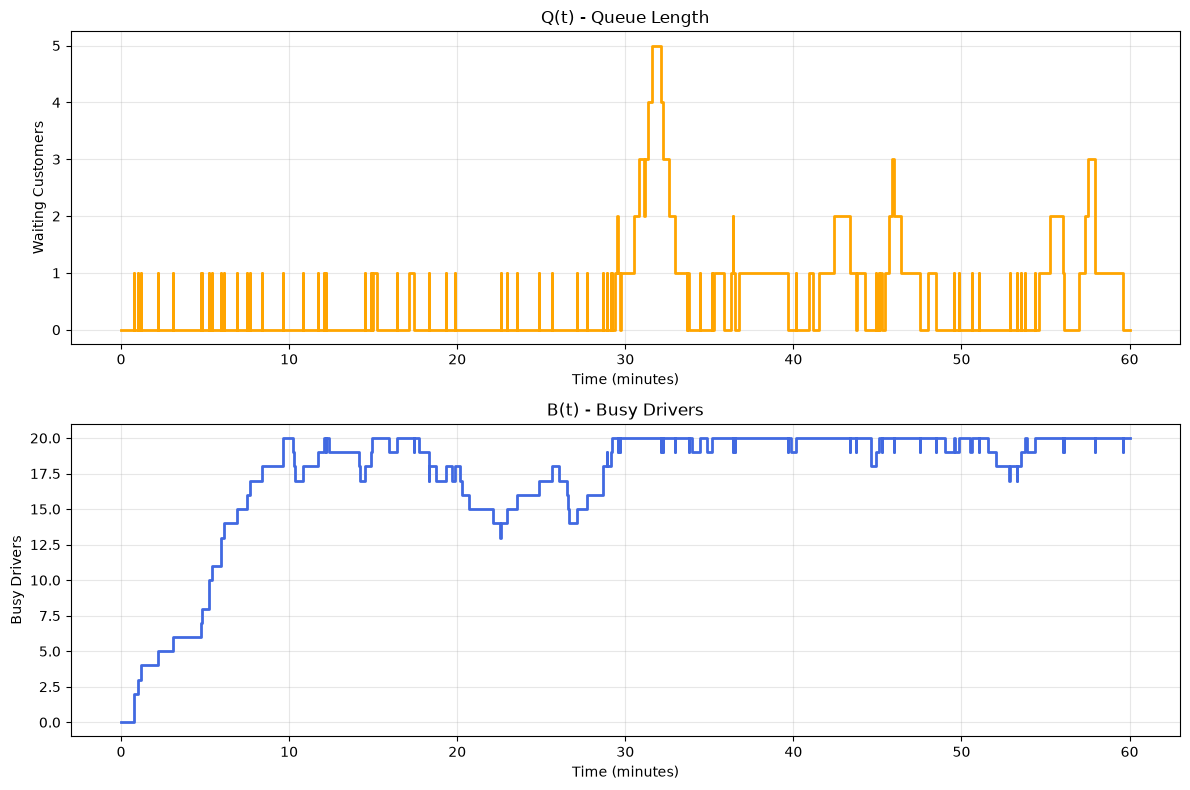

In [5]:

# 6. Q(t) and B(t) Plots

fig = plot_q_b(event_history)
plt.show()



## 7. Results and Interpretation

During the 60-minute simulation, a total of 86 customer requests were generated. Among these requests, 78 customers were assigned to drivers, 58 completed their trips, and 8 abandoned the system. The remaining 20 customers were still in service at the end of the simulation.

The average queue delay for assigned customers was 0.28 minutes, while the average time in the system for completed customers was 15.01 minutes.

Driver utilization reached 86.65%, indicating a high level of fleet usage. The abandonment rate was 9.30%.

The Q(t) graph illustrates fluctuations in the number of waiting customers, reaching a maximum of approximately five customers.

The B(t) graph demonstrates that the number of busy drivers frequently reaches the fleet capacity of 20, particularly during the second half of the simulation.

These preliminary results suggest that increasing fleet capacity may reduce customer waiting times and abandonment. However, additional simulation runs with different random seeds, fleet sizes, and dispatch policies are required to draw reliable conclusions.



## 8. Assumptions, distributions and SimPy lifecycle

The baseline uses a homogeneous Poisson arrival process (exponential interarrival
mean 0.75 min), exponential patience (mean 5 min), Uniform(2,8) pickup, and
lognormal trip duration (arithmetic mean 10 min, log standard deviation 0.5).
The lognormal normal-location parameter is log(10) - 0.5**2/2. Patience is sampled
once at arrival; its individual values are not bounded to 3-8 minutes.

Each customer is a SimPy process. A Resource gates FIFO access to 20 drivers;
request versus timeout determines assignment or pre-assignment abandonment.
Expiry wins an exact deadline tie. A valid grant atomically reserves a named
driver, selected randomly or by minimum Euclidean pickup distance (lowest ID
breaks ties). The driver stays busy during pickup and trip, moves to the destination
at completion, then releases capacity. The run stops at an exclusive horizon;
unfinished customers are censored and the system is not drained.

Coordinates are abstract planar units, not calibrated road geography. Optional
distance-aware pickup = base delay + distance/speed is already merged in PR #10;
it is analyzed separately from the unchanged uniform baseline. Trips remain
independent of route distance. The city viewer is schematic replay, not a routing model.

The following graph is embedded verbatim from EVENT_GRAPH.md, including both
pickup modes; the same-time capacity callbacks do not add a second customer queue.

```mermaid
flowchart TD
    start([Simulation Start])
    arrival([Customer Arrival])
    request["Request driver capacity"]
    outcome{"Capacity granted strictly before patience deadline?"}
    policy{"Dispatch Policy"}
    random["Select random available driver"]
    nearest["Select nearest available driver"]
    assign([Driver Assignment])
    abandon([Customer Abandonment])
    pickup([Pickup Completion])
    trip([Trip Completion])
    release["Release driver and update position"]
    finish([Simulation End])

    start -->|"First interarrival time"| arrival
    arrival -->|"Exponential interarrival time"| arrival
    arrival --> request
    request -->|"FIFO queue: wait for grant or expiry"| outcome
    outcome -->|"Yes"| policy
    outcome -->|"Expiry first or exact tie"| abandon
    policy -->|"Random"| random
    policy -->|"Nearest"| nearest
    random --> assign
    nearest --> assign
    assign -->|"Configured pickup: Uniform(2,8) baseline or overhead + distance/speed"| pickup
    pickup -->|"Lognormal trip duration: mean 10 min"| trip
    trip --> release
    release -.->|"Next FIFO request may receive capacity"| outcome
    start -->|"Configured simulation horizon"| finish
```

## 9. Metric populations and denominators

| Metric | Observation and denominator |
|---|---|
| Queue delay | Assignment minus arrival, averaged over all assigned customers, including unfinished pickup/trip |
| Time in system | Completion minus arrival, completed trips only |
| Mean Q | Integral Q(t) dt / horizon |
| Mean N | Integral N(t) dt / horizon; N = waiting + pickup + trip |
| Utilization | Integral B(t) dt / (fleet size * horizon) |
| Abandonment | Abandoned / all arrivals, including censored arrivals |
| Assignment distance | Euclidean driver-to-pickup distance, averaged over assigned customers |

Time integrals use post-event states in (time, sequence) order. Same-time events
have zero interval; the last state persists to the next timestamp and through
the horizon. No statistics are duplicated here: calculations call metrics.py.
Empty customer means have count zero in the core; replication tools represent
these as None and exclude them explicitly, reporting n and missing for every CI.
An empty-run abandonment fraction is also missing; empty time averages are zero.
The following independent per-customer exposure check verifies the history integrals.

In [6]:
from math import fsum

def exposure(start, end):
    return max(0, min(horizon, end if end is not None else horizon) - start)

q_area = fsum(exposure(r.arrival_time, r.driver_assignment_time if r.driver_assignment_time is not None else r.abandonment_time)
              for r in requests)
n_area = fsum(exposure(r.arrival_time, r.completion_time if r.completion_time is not None else r.abandonment_time)
              for r in requests)
b_area = fsum(exposure(r.driver_assignment_time, r.completion_time)
              for r in requests if r.driver_assignment_time is not None)
assert abs(q_area/horizon - avg_queue) < 1e-12
assert abs(n_area/horizon - avg_system) < 1e-12
assert abs(b_area/(config.fleet_size*horizon) - utilization) < 1e-12
print('Independent ledger exposure checks passed:', q_area, n_area, b_area)

Independent ledger exposure checks passed: 27.695195359755182 1067.5315402413632 1039.836344881608


## 10. Independent replications and 95% confidence intervals

Eight local Python RNGs use abs(seed)+0..7. Consecutive base seeds would overlap.
Replication i instead uses base abs(master_seed)+8*i. Streams within and across
replications have distinct seed values. Matched experimental cells intentionally
reuse each replication's bundle as common random numbers; independent units for
inference are replication IDs (or paired differences), never individual customers.
To extend a batch, keep its master seed and continue with start_index; merely
changing master seeds does not guarantee nonoverlap.

For n nonmissing replication values: sample standard deviation uses n-1,
SE = s/sqrt(n), and CI = mean +/- t(n-1,0.975)*SE. No internal rounding or clipping
of intervals is applied. n < 2 has no interval; zero variance has zero half-width.
These finite-run, initially empty experiments use no warm-up or steady-state claim.
Run-level averages give each run equal weight; they are not pooled customer means.
Intervals with missing populations describe runs where that statistic is defined.

In [7]:
from dataclasses import asdict
from inference import confidence_interval, estimate_replications
from replications import run_replications, summarize_replications

numerical_ci = confidence_interval([1, 2, 3, 4, 5])
assert abs(numerical_ci.half_width - 1.963243161477561) < 1e-10
print('Independent numerical CI example:', asdict(numerical_ci))
pilot = run_replications(config, 20, master_seed=2026)
for name, interval in summarize_replications(pilot).items():
    print(name, interval)

Independent numerical CI example: {'confidence': 0.95, 'n': 5, 'missing': 0, 'mean': 3, 'standard_deviation': 1.5811388300841898, 'standard_error': 0.7071067811865476, 'lower': 1.0367568385224428, 'upper': 4.963243161477557, 'half_width': 1.9632431614775572}
average_queue_delay {'confidence': 0.95, 'n': 20, 'missing': 0, 'mean': 0.34436399954104624, 'standard_deviation': 0.20935500647925995, 'standard_error': 0.046813202591753415, 'lower': 0.24638284045261696, 'upper': 0.44234515862947554, 'half_width': 0.09798115908842928}
average_time_in_system {'confidence': 0.95, 'n': 20, 'missing': 0, 'mean': 14.56543091182592, 'standard_deviation': 0.7980866697168474, 'standard_error': 0.17845760454232934, 'lower': 14.19191485282674, 'upper': 14.938946970825102, 'half_width': 0.3735160589991808}
time_average_queue_length {'confidence': 0.95, 'n': 20, 'missing': 0, 'mean': 0.6132323983971122, 'standard_deviation': 0.3796425231723307, 'standard_error': 0.08489064889628706, 'lower': 0.43555422826285

## 11. Beta precision planning

The instructor's original definition of beta is unavailable in the repository.
We ASSUME beta means an absolute CI half-width in the metric's units. This is not
confirmed instructor wording, relative error, or Type II error. The configurable
estimator finds the smallest total n >= pilot n satisfying
t(n-1,0.975)*s_pilot/sqrt(n) <= beta by binary search, holding pilot variance fixed.
It records confidence, beta, usable/missing pilot counts, variance, estimated n,
predicted half-width, and whether the configured cap can meet the target.
No optional stopping is performed. The fixed-size experiment remains 20 replications;
the estimate plans a subsequent fixed-size batch and does not promise achieved
precision. Zero pilot variance retains the pilot size but does not prove certainty.

In [8]:
example_plan = estimate_replications([1, 2, 3, 4, 5], beta=1.0)
assert example_plan.required_replications == 13
print('Numerical plan (pilot variance 2.5, beta=1):', asdict(example_plan))
abandonment_plan = estimate_replications([r.metrics['abandonment_rate'] for r in pilot], beta=0.05)
print('60-minute pilot abandonment plan (beta = 5 percentage points):', asdict(abandonment_plan))

Numerical plan (pilot variance 2.5, beta=1): {'confidence': 0.95, 'target_half_width': 1.0, 'pilot_sample_size': 5, 'missing': 0, 'estimated_variance': 2.5000000000000004, 'required_replications': 13, 'estimated_half_width': 0.9554726324143417, 'max_replications': 1000000, 'target_reachable': True}
60-minute pilot abandonment plan (beta = 5 percentage points): {'confidence': 0.95, 'target_half_width': 0.05, 'pilot_sample_size': 20, 'missing': 0, 'estimated_variance': 0.0021230165462386044, 'required_replications': 20, 'estimated_half_width': 0.02156432711882065, 'max_replications': 1000000, 'target_reachable': True}


## 12. Replicated experimental design and reproducible results

Five fleet/demand settings (baseline, low/high demand, small/large fleet) are
crossed with random/nearest dispatch and uniform/distance-aware pickup: 20 cells.
Each uses 20 replications of 240 minutes, master seed 2026, starting empty.
Demand means are 1.5, 0.75, 0.25 min; fleet sizes 5, 20, 40. This is a baseline
with one-factor demand/fleet contrasts, not a full demand-by-fleet factorial.
Policy and mode are crossed at each setting. All seven metrics and their 95%
intervals are computed. Paired differences are alternative minus reference.
Factor contrasts change exactly one configured factor; they are conditional on
the other fixed assumptions. No multiple-comparison adjustment or universal
policy superiority is claimed.

The next cell reruns the complete design and checks agreement (float tolerance 1e-10 relative / 1e-12 absolute across platforms) with the
committed JSON. The CSV contains every run's configuration, IDs, seeds, counts
and metrics; it can be regenerated with the documented experiments.py command.

In [9]:
import json
from pathlib import Path
from experiments import assert_report_matches, default_design, run_experiment

experiment = run_experiment(default_design(240), 20, master_seed=2026)
recorded = json.loads(Path('docs/results/week3_experiment.json').read_text(encoding='utf8'))
assert_report_matches(experiment, recorded)
print('Reproduced 400 runs, all seven metrics, intervals and paired contrasts.')
for name in ('baseline/uniform/random', 'baseline/uniform/nearest',
             'baseline/distance_aware/random', 'baseline/distance_aware/nearest'):
    print('\n', name)
    for metric, interval in experiment['summaries'][name].items():
        print(metric, 'mean=', interval['mean'], '95% CI=', (interval['lower'], interval['upper']))

Reproduced 400 runs, all seven metrics, intervals and paired contrasts.

 baseline/uniform/random
average_queue_delay mean= 0.4718381670660262 95% CI= (0.38694008421059545, 0.556736249921457)
average_time_in_system mean= 15.256424712645934 95% CI= (15.022840633086016, 15.490008792205852)
time_average_queue_length mean= 0.7353184269430212 95% CI= (0.5939041122792765, 0.8767327416067658)
time_average_number_in_system mean= 18.105131876394548 95% CI= (17.725062837633384, 18.485200915155712)
driver_utilization mean= 0.8684906724725763 95% CI= (0.8551036136669031, 0.8818777312782494)
abandonment_rate mean= 0.10483604025933142 95% CI= (0.08976963680497713, 0.11990244371368572)
mean_assignment_distance mean= 5.252044191580323 95% CI= (5.203694495512084, 5.3003938876485615)

 baseline/uniform/nearest
average_queue_delay mean= 0.4718381670660262 95% CI= (0.38694008421059545, 0.556736249921457)
average_time_in_system mean= 15.256424712645934 95% CI= (15.022840633086016, 15.490008792205852)
time_

In [10]:
from IPython.display import Markdown, display

lines = ['| Contrast (alternative - reference) | Metric | Mean | 95% CI |',
         '|---|---|---:|---|']
for name, contrasts in experiment['policy_comparisons'].items():
    for metric in ('mean_assignment_distance', 'average_queue_delay', 'abandonment_rate'):
        ci = contrasts[metric]
        lines.append(f"| {name} | {metric} | {ci['mean']:.5f} | [{ci['lower']:.5f}, {ci['upper']:.5f}] |")
display(Markdown('\n'.join(lines)))
for name, contrast in experiment['factor_comparisons'].items():
    ci = contrast['metrics']['abandonment_rate']
    print(name, contrast['factor'], 'abandonment difference:', ci['mean'], (ci['lower'], ci['upper']))
print('240-minute beta planning:', experiment['beta_planning']['baseline/uniform/random'])

| Contrast (alternative - reference) | Metric | Mean | 95% CI |
|---|---|---:|---|
| baseline/uniform/nearest - baseline/uniform/random | mean_assignment_distance | -1.14923 | [-1.25516, -1.04330] |
| baseline/uniform/nearest - baseline/uniform/random | average_queue_delay | 0.00000 | [0.00000, 0.00000] |
| baseline/uniform/nearest - baseline/uniform/random | abandonment_rate | 0.00000 | [0.00000, 0.00000] |
| baseline/distance_aware/nearest - baseline/distance_aware/random | mean_assignment_distance | -1.24179 | [-1.36503, -1.11855] |
| baseline/distance_aware/nearest - baseline/distance_aware/random | average_queue_delay | -0.16350 | [-0.20091, -0.12610] |
| baseline/distance_aware/nearest - baseline/distance_aware/random | abandonment_rate | -0.03515 | [-0.03995, -0.03035] |
| low_demand/uniform/nearest - low_demand/uniform/random | mean_assignment_distance | -3.06987 | [-3.17496, -2.96479] |
| low_demand/uniform/nearest - low_demand/uniform/random | average_queue_delay | 0.00000 | [0.00000, 0.00000] |
| low_demand/uniform/nearest - low_demand/uniform/random | abandonment_rate | 0.00000 | [0.00000, 0.00000] |
| low_demand/distance_aware/nearest - low_demand/distance_aware/random | mean_assignment_distance | -3.24642 | [-3.34916, -3.14368] |
| low_demand/distance_aware/nearest - low_demand/distance_aware/random | average_queue_delay | -0.01520 | [-0.02864, -0.00175] |
| low_demand/distance_aware/nearest - low_demand/distance_aware/random | abandonment_rate | -0.00333 | [-0.00685, 0.00019] |
| high_demand/uniform/nearest - high_demand/uniform/random | mean_assignment_distance | -0.17783 | [-0.19661, -0.15905] |
| high_demand/uniform/nearest - high_demand/uniform/random | average_queue_delay | 0.00000 | [0.00000, 0.00000] |
| high_demand/uniform/nearest - high_demand/uniform/random | abandonment_rate | 0.00000 | [0.00000, 0.00000] |
| high_demand/distance_aware/nearest - high_demand/distance_aware/random | mean_assignment_distance | -0.20255 | [-0.27710, -0.12801] |
| high_demand/distance_aware/nearest - high_demand/distance_aware/random | average_queue_delay | -0.08813 | [-0.18275, 0.00650] |
| high_demand/distance_aware/nearest - high_demand/distance_aware/random | abandonment_rate | -0.00371 | [-0.00521, -0.00222] |
| small_fleet/uniform/nearest - small_fleet/uniform/random | mean_assignment_distance | -0.07920 | [-0.10805, -0.05035] |
| small_fleet/uniform/nearest - small_fleet/uniform/random | average_queue_delay | 0.00000 | [0.00000, 0.00000] |
| small_fleet/uniform/nearest - small_fleet/uniform/random | abandonment_rate | 0.00000 | [0.00000, 0.00000] |
| small_fleet/distance_aware/nearest - small_fleet/distance_aware/random | mean_assignment_distance | -0.05984 | [-0.22216, 0.10248] |
| small_fleet/distance_aware/nearest - small_fleet/distance_aware/random | average_queue_delay | -0.06645 | [-0.20557, 0.07267] |
| small_fleet/distance_aware/nearest - small_fleet/distance_aware/random | abandonment_rate | 0.00009 | [-0.00193, 0.00211] |
| large_fleet/uniform/nearest - large_fleet/uniform/random | mean_assignment_distance | -3.73364 | [-3.83314, -3.63415] |
| large_fleet/uniform/nearest - large_fleet/uniform/random | average_queue_delay | 0.00000 | [0.00000, 0.00000] |
| large_fleet/uniform/nearest - large_fleet/uniform/random | abandonment_rate | 0.00000 | [0.00000, 0.00000] |
| large_fleet/distance_aware/nearest - large_fleet/distance_aware/random | mean_assignment_distance | -3.88825 | [-3.95771, -3.81879] |
| large_fleet/distance_aware/nearest - large_fleet/distance_aware/random | average_queue_delay | -0.00114 | [-0.00352, 0.00124] |
| large_fleet/distance_aware/nearest - large_fleet/distance_aware/random | abandonment_rate | -0.00014 | [-0.00042, 0.00015] |

baseline/distance_aware/random - baseline/uniform/random pickup_mode abandonment difference: 0.039765870939434296 (0.035085177306570375, 0.04444656457229822)
low_demand/uniform/random - baseline/uniform/random mean_interarrival_minutes abandonment difference: -0.102613380935964 (-0.11588528412971522, -0.0893414777422128)
high_demand/uniform/random - baseline/uniform/random mean_interarrival_minutes abandonment difference: 0.5417863528011436 (0.5301945705991095, 0.5533781350031778)
small_fleet/uniform/random - baseline/uniform/random fleet_size abandonment difference: 0.6265066571602625 (0.616171991287261, 0.6368413230332641)
large_fleet/uniform/random - baseline/uniform/random fleet_size abandonment difference: -0.10483604025933142 (-0.11990244371368572, -0.08976963680497713)
baseline/distance_aware/nearest - baseline/uniform/nearest pickup_mode abandonment difference: 0.004619840949046211 (-0.002240355275797523, 0.011480037173889944)
low_demand/uniform/nearest - baseline/uniform/neare

## 13. Conclusions and limitations

In uniform mode, matched Random and Nearest runs have exactly equal queue/system
timing, Q/N, utilization and abandonment: pickup and trip duration streams do not
depend on driver identity or assignment distance. Policy changes distance only;
the paired zero timing intervals reflect this structure, not evidence that spatial
dispatch can never affect a real system. Distance-aware mode explicitly couples
distance and pickup time and is reported separately above. The effect of nearest
selection depends on fleet size and demand because earlier choices change later
idle candidates and driver positions; it is not guaranteed to improve every run.

Demand/fleet contrasts above report replicated differences and uncertainty.
An interval containing zero is inconclusive at the stated pointwise level;
one excluding zero is evidence conditional on this model and experimental design.
Finite-horizon customer means exclude censored and abandoned outcomes as defined,
so a lower served-customer delay alone does not establish better service for all
arrivals. No customer pooling or single-seed policy conclusions are used.

Limitations: initially empty finite runs, illustrative uncalibrated spatial speed
and overhead, Euclidean geometry, route-independent lognormal trips, schematic
animation, potentially nonnormal replication outputs, and unadjusted multiple
comparisons. Instructor beta semantics remain unresolved. A final report,
presentation and polished bonus animation are separate submission deliverables;
this notebook does not claim them complete. The deadline supplied for the project
is December 16, 2026; no original instructor week-by-week schedule is available.

Statistical API reference: [SciPy Student-t](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html).